# Phase 7 — Customer Segment Interpretation and Business Insights
**Project:** AI-Based Customer Segmentation and Purchasing Behaviour Analysis Using Machine Learning

## Objective
Interpret the K-Means clusters from Phase 5 using customer-level Recency, Frequency, and Monetary values. Create evidence-based descriptive segment names and explain possible business uses.

## Input files
- `Phase4_Customer_RFM.csv`
- `Phase5_Customer_Clusters.csv` (primary K-Means labels). Labels are joined to customers by **CustomerID**, never by row position. If the file is missing, or any customer cannot be matched, this notebook refits the documented K-Means K=3 pipeline instead.

## Important
Segment names are descriptive interpretations, not known ground-truth customer categories. Imported labels are joined by CustomerID and validated one-to-one. Recency is days since the reference date; Frequency is distinct valid invoices; Monetary is positive-purchase line value under the Phase 3 cancellation/non-positive-line policy.

In [1]:
import os
from pathlib import Path
# Work inside data/processed (found from the notebook folder upwards); paths below are relative to it.
for _d in [Path.cwd(), *Path.cwd().parents]:
    if (_d / "data" / "processed").is_dir():
        os.chdir(_d / "data" / "processed")
        break
print("Data folder:", Path.cwd().name)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RFM_FILE = Path("Phase4_Customer_RFM.csv")
CLUSTERS_FILE = Path("Phase5_Customer_Clusters.csv")
FIG_DIR = Path("../../artifacts/phase_outputs/phase7_outputs")
FIG_DIR.mkdir(exist_ok=True)
rfm = pd.read_csv(RFM_FILE)
for c in ["Recency", "Frequency", "Monetary"]:
    rfm[c] = pd.to_numeric(rfm[c], errors="coerce")
rfm = rfm.dropna(subset=["Recency", "Frequency", "Monetary"]).copy()
assert rfm["CustomerID"].is_unique

# Use the saved Phase 5 labels, joined by CustomerID (one-to-one); otherwise refit the documented pipeline.
label_source = None
if CLUSTERS_FILE.exists():
    saved = pd.read_csv(CLUSTERS_FILE)
    if {"CustomerID", "Cluster"}.issubset(saved.columns) and saved["CustomerID"].is_unique:
        joined = rfm.merge(saved[["CustomerID", "Cluster"]], on="CustomerID", how="left", validate="one_to_one")
        if joined["Cluster"].notna().all() and len(saved) == len(rfm):
            rfm = joined.rename(columns={"Cluster": "KMeans_Cluster"})
            rfm["KMeans_Cluster"] = rfm["KMeans_Cluster"].astype(int)
            label_source = "Phase5_Customer_Clusters.csv (joined by CustomerID)"

if label_source is None:
    from sklearn.preprocessing import StandardScaler
    from sklearn.cluster import KMeans
    features = rfm[["Recency", "Frequency", "Monetary"]].copy()
    features["Frequency"] = np.log1p(features["Frequency"])
    features["Monetary"] = np.log1p(features["Monetary"])
    X = StandardScaler().fit_transform(features)
    rfm["KMeans_Cluster"] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)
    label_source = "refitted documented K-Means pipeline (K=3, random_state=42, n_init=10)"

print("Label source:", label_source)
print("RFM customers:", len(rfm))
print("Cluster counts:")
display(rfm["KMeans_Cluster"].value_counts().sort_index())


Data folder: processed


Label source: Phase5_Customer_Clusters.csv (joined by CustomerID)
RFM customers: 4338
Cluster counts:


KMeans_Cluster
0    2038
1     980
2    1320
Name: count, dtype: int64

In [2]:
def make_profile(data):
    return data.groupby("KMeans_Cluster").agg(
        Customers=("CustomerID", "count"),
        Recency_Median=("Recency", "median"),
        Frequency_Median=("Frequency", "median"),
        Monetary_Median=("Monetary", "median"),
        Recency_Mean=("Recency", "mean"),
        Frequency_Mean=("Frequency", "mean"),
        Monetary_Mean=("Monetary", "mean"),
        Recency_P25=("Recency", lambda s: s.quantile(0.25)),
        Recency_P75=("Recency", lambda s: s.quantile(0.75)),
        Frequency_P25=("Frequency", lambda s: s.quantile(0.25)),
        Frequency_P75=("Frequency", lambda s: s.quantile(0.75)),
        Monetary_P25=("Monetary", lambda s: s.quantile(0.25)),
        Monetary_P75=("Monetary", lambda s: s.quantile(0.75)),
    ).reset_index()

profile = make_profile(rfm)
profile["Customer_Percent"] = 100 * profile["Customers"] / len(rfm)
overall = rfm[["Recency", "Frequency", "Monetary"]].median()

def suggest_name(row):
    recent = row["Recency_Median"] < overall["Recency"]
    frequent = row["Frequency_Median"] > overall["Frequency"]
    high_spend = row["Monetary_Median"] > overall["Monetary"]
    if recent and frequent and high_spend:
        return "Recent, Frequent, High-Spend Customers"
    if recent and frequent:
        return "Recent, Frequent Customers"
    if recent and high_spend:
        return "Recent, High-Spend Customers"
    if frequent and high_spend:
        return "Frequent, High-Spend Customers"
    if row["Recency_Median"] > overall["Recency"] and row["Frequency_Median"] < overall["Frequency"]:
        return "At-Risk / Inactive, Low-Frequency Customers"
    if row["Recency_Median"] > overall["Recency"]:
        return "Less-Recent Customers"
    return "Occasional / Lower-Spend Customers"

profile["Suggested_Segment_Name"] = profile.apply(suggest_name, axis=1)
# Strict inequalities: a cluster whose median only equals the population median is not called "frequent"/"high-spend".
print("Population medians used as thresholds:", overall.to_dict())
assert profile["Suggested_Segment_Name"].is_unique, "Two clusters received the same descriptive name"
assert abs(profile["Customer_Percent"].sum() - 100) < 1e-9 and profile["Customers"].sum() == len(rfm)
rfm["Segment"] = rfm["KMeans_Cluster"].map(profile.set_index("KMeans_Cluster")["Suggested_Segment_Name"])

# The names must agree with the Phase 5 profile-based names when Phase 5 labels were used.
if CLUSTERS_FILE.exists() and "Segment" in saved.columns and label_source.startswith("Phase5"):
    chk = rfm[["CustomerID", "Segment"]].merge(saved[["CustomerID", "Segment"]], on="CustomerID", suffixes=("", "_Phase5"))
    assert (chk["Segment"] == chk["Segment_Phase5"]).all(), "Phase 7 names disagree with Phase 5 names"
    print("Segment names agree with Phase 5 for all", len(chk), "customers")
display(profile.round(2))


Population medians used as thresholds: {'Recency': 51.0, 'Frequency': 2.0, 'Monetary': 668.5699999999999}
Segment names agree with Phase 5 for all 4338 customers


,KMeans_Cluster,Customers,Recency_Median,Frequency_Median,Monetary_Median,Recency_Mean,Frequency_Mean,Monetary_Mean,Recency_P25,Recency_P75,Frequency_P25,Frequency_P75,Monetary_P25,Monetary_P75,Customer_Percent,Suggested_Segment_Name
0,0,2038,46.0,2.0,508.80,55.31,2.05,612.67,22.0,79.0,1.0,3.0,286.12,801.30,46.98,Occasional / Lower-Spend Customers
1,1,980,253.0,1.0,290.46,255.70,1.39,397.03,201.0,306.0,1.0,2.0,155.92,459.04,22.59,"At-Risk / Inactive, Low-Frequency Customers"
2,2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,8.0,38.0,5.0,11.0,1689.77,4303.42,30.43,"Recent, Frequent, High-Spend Customers"


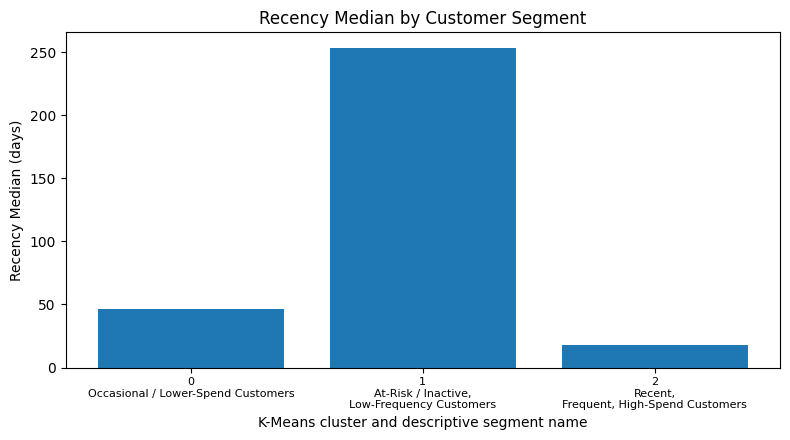

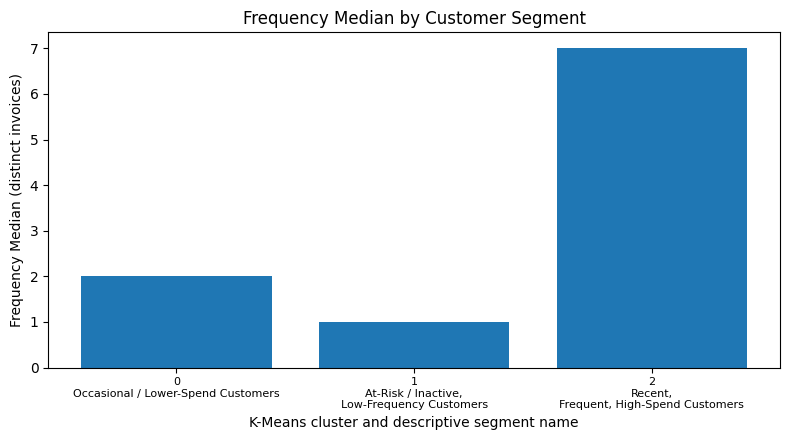

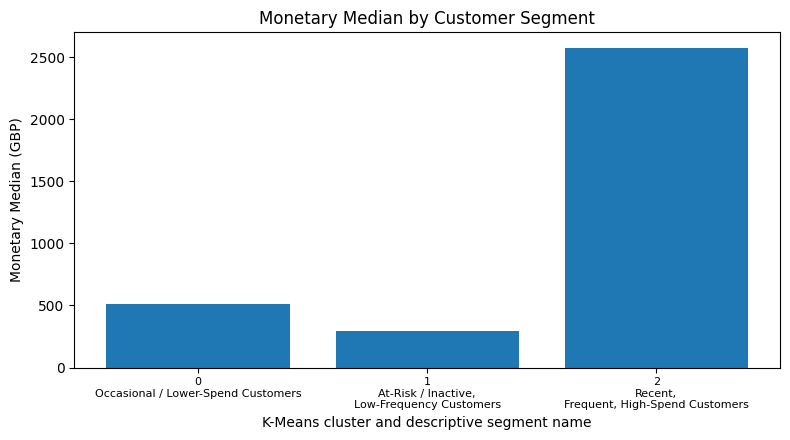

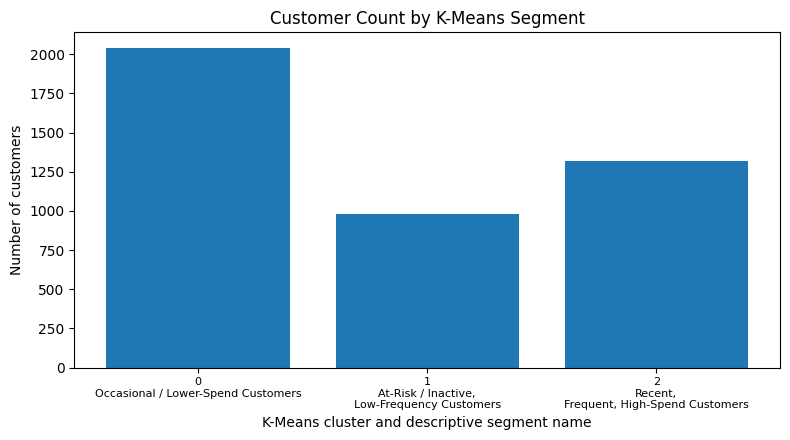

In [3]:
# Visualise the median RFM profile for each cluster
labels_axis = [f"{c}\n{n}" for c, n in zip(profile["KMeans_Cluster"], profile["Suggested_Segment_Name"].str.replace(", ", ",\n", n=1))]
units = {"Recency_Median": "days", "Frequency_Median": "distinct invoices", "Monetary_Median": "GBP"}
for metric in ["Recency_Median", "Frequency_Median", "Monetary_Median"]:
    plt.figure(figsize=(8, 4.5))
    plt.bar(labels_axis, profile[metric])
    plt.xlabel("K-Means cluster and descriptive segment name")
    plt.ylabel(f"{metric.replace('_', ' ')} ({units[metric]})")
    plt.title(f"{metric.replace('_', ' ')} by Customer Segment")
    plt.xticks(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{metric.lower()}_by_segment.png", dpi=150)
    plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(labels_axis, profile["Customers"])
plt.xlabel("K-Means cluster and descriptive segment name")
plt.ylabel("Number of customers")
plt.title("Customer Count by K-Means Segment")
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "customers_by_segment.png", dpi=150)
plt.show()

In [4]:
# Save the Phase 7 outputs
profile.to_csv("Phase7_KMeans_Segment_Profiles.csv", index=False, lineterminator="\n")
rfm.to_csv("Phase7_Customer_Segment_Labels.csv", index=False, lineterminator="\n")
print("Saved Phase 7 segment profiles, customer labels and figures in", FIG_DIR)

Saved Phase 7 segment profiles, customer labels and figures in ..\..\artifacts\phase_outputs\phase7_outputs


## Business interpretation guide
- Lower Recency means the customer purchased more recently.
- Higher Frequency means the customer placed more distinct valid orders.
- Higher Monetary means greater recorded positive-purchase value under the project's policy.
- Use the profiles to propose retention, re-engagement, loyalty, or cross-selling actions; these are recommendations, not causal findings.
- Cluster numbers are arbitrary. Segment names should follow the observed profile, not the cluster ID.
- Median comparisons use the overall customer median as a simple descriptive rule (strict inequalities), not a validated business threshold.
- Validate recommendations with business outcomes before deployment.